# Exercício 4 · Qui-quadrado: o questionário de perfil do Rende

**Disciplina 4 · Testes de Hipótese e Experimentação · Pós-graduação em Ciência de Dados e IA · UNIPDS**

**GABARITO** · com prompts, código e leituras comentadas.

## O contexto

O **Rende** é um app de investimentos. Antes de investir, todo cliente responde um **questionário de perfil**, que o classifica como **conservador**, **moderado** ou **arrojado**. O perfil define quais produtos o app pode oferecer a ele.

O questionário atual tem 12 perguntas, e muita gente desiste no meio. O time de Produto criou duas versões novas:

| Versão | O questionário |
|:---|:---|
| `A_atual` | 12 perguntas, só texto (controle) |
| `B_curto` | 6 perguntas, só texto |
| `C_visual` | 12 perguntas, com exemplos visuais de ganhos e perdas |

**A preocupação do time de Compliance:** mudar o questionário não pode mudar o perfil das pessoas. Se a versão curta, por exemplo, deixasse mais gente "arrojada", o app passaria a oferecer produtos de risco a quem não deveria recebê-los. Antes de trocar o questionário, o time quer saber: **a distribuição de perfis muda com a versão?**

**Os dados** · `experimento_questionario_perfil.csv`, uma linha por cliente sorteado (1/3 de chance para cada versão).

| Coluna | Descrição |
|:---|:---|
| `user_id` | Identificador do cliente |
| `versao` | Versão sorteada do questionário |
| `perfil` | Resultado do questionário: `conservador`, `moderado` ou `arrojado` |

### Como usar este gabarito

Cada passo tem o **prompt** usado, o código gerado e a **leitura** do resultado. Os prompts são um exemplo: o importante é que digam **o que** a análise precisa fazer, não **como** codificar.

## Parte 1 · As hipóteses

| Ingrediente | Valor |
|:---|:---|
| H0 | A versão do questionário e o perfil são **independentes**: a distribuição entre conservador, moderado e arrojado é a mesma nas três versões |
| Ha | A versão e o perfil estão **associados**: em pelo menos uma versão, a distribuição é diferente |
| Teste | Qui-quadrado de independência |
| α | 5% |

**Por que qui-quadrado?** A métrica é **categórica**, com três categorias, e há **três grupos**. O teste z de duas proporções só compara dois grupos e duas categorias. O qui-quadrado responde com um único teste se a distribuição de perfis muda entre as versões.

## Parte 2 · Os dados

**Prompt para a IA**

> Vou fazer um teste qui-quadrado em Python. Carregue as bibliotecas de dados, gráficos e estatística (use funções prontas e um código simples, para iniciantes). Depois, leia o arquivo experimento_questionario_perfil.csv, mostre as primeiras linhas e quantos clientes caíram em cada versão.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

df = pd.read_csv("experimento_questionario_perfil.csv")
print(df.head())
print()
print(df["versao"].value_counts().sort_index())

   user_id    versao       perfil
0   700001  C_visual     arrojado
1   700002  C_visual     arrojado
2   700003   A_atual     moderado
3   700004  C_visual  conservador
4   700005   B_curto     arrojado

versao
A_atual     600
B_curto     616
C_visual    584
Name: count, dtype: int64


> **Leitura.** São 1.800 clientes, divididos em grupos de tamanhos parecidos: 600 na versão A, 616 na B e 584 na C.

**Prompt para a IA**

> Monte a tabela de contingência entre a versão do questionário e o perfil (na ordem conservador, moderado, arrojado), com as contagens. Mostre também as porcentagens de cada perfil dentro de cada versão e um gráfico de barras empilhadas com essas porcentagens.

perfil    conservador  moderado  arrojado
versao                                   
A_atual           262       239        99
B_curto           290       224       102
C_visual          247       239        98

perfil    conservador  moderado  arrojado
versao                                   
A_atual          43.7      39.8      16.5
B_curto          47.1      36.4      16.6
C_visual         42.3      40.9      16.8


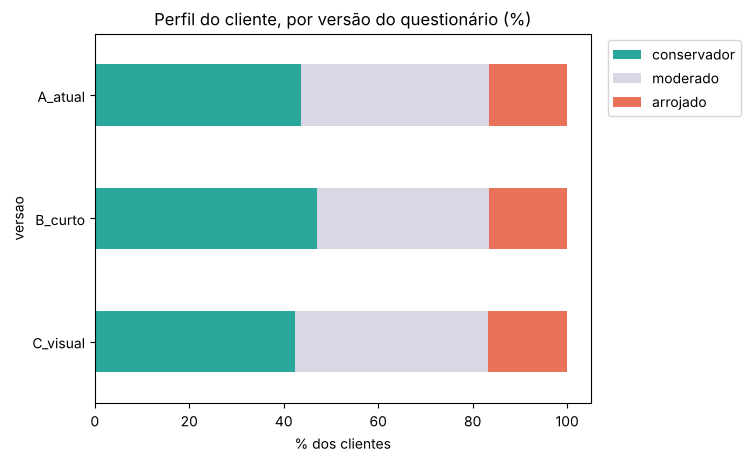

In [2]:
ordem = ["conservador", "moderado", "arrojado"]

tabela = pd.crosstab(df["versao"], df["perfil"])[ordem]
print(tabela)

porcentagens = pd.crosstab(df["versao"], df["perfil"], normalize="index")[ordem] * 100
print()
print(porcentagens.round(1))

porcentagens.plot.barh(stacked=True, color=["#2AA79B", "#D9D6E6", "#E8735A"])
plt.gca().invert_yaxis()
plt.title("Perfil do cliente, por versão do questionário (%)")
plt.xlabel("% dos clientes")
plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left")
plt.show()

> **Leitura.** As três versões têm distribuições parecidas: entre 42% e 47% de conservadores, 36% a 41% de moderados e cerca de 17% de arrojados. A maior diferença está na versão curta (B), com 47,1% de conservadores, contra 43,7% da atual. Isso é efeito do questionário ou só acaso? É o que o teste vai responder.

## Parte 3 · O teste qui-quadrado

**Prompt para a IA**

> Aplique o teste qui-quadrado de independência à tabela de contingência. Mostre a estatística qui-quadrado, os graus de liberdade, o p-valor e a tabela de frequências esperadas sob H0, e confira se todas as esperadas são de pelo menos 5.

In [ ]:
resultado = stats.chi2_contingency(tabela)
print(f"Qui-quadrado = {resultado.statistic:.2f} · gl = {resultado.dof} · p-valor = {resultado.pvalue:.2f}")

esperadas = pd.DataFrame(resultado.expected_freq, index=tabela.index, columns=tabela.columns)
print()
print(esperadas.round(1))
print(f"\nMenor frequência esperada: {esperadas.values.min():.1f}")

Qui-quadrado = 3.43 · gl = 4 · p-valor = 0.49

perfil    conservador  moderado  arrojado
versao                                   
A_atual         266.3     234.0      99.7
B_curto         273.4     240.2     102.3
C_visual        259.2     227.8      97.0

Menor frequência esperada: 97.0


> **Leitura.** χ² = 3,43, com (3 − 1) × (3 − 1) = 4 graus de liberdade, e **p = 0,49**. A menor frequência esperada é de 97 clientes, bem acima de 5: a aproximação é confiável.
>
> No multiverso em que a versão do questionário não muda o perfil, quase metade dos experimentos daria uma tabela tão ou mais desequilibrada que esta. **Não rejeitamos H0**: não há evidência de que a versão do questionário muda a distribuição de perfis. Os 47,1% de conservadores da versão curta cabem no acaso.

## Parte 4 · A decisão

**Recomendação.** O teste não encontrou evidência de que as versões novas mudam a distribuição de perfis (χ² = 3,43, p = 0,49). Do ponto de vista de Compliance, não há sinal de problema com B ou C.

**Um cuidado importante:** "não rejeitar H0" não é "provar que as distribuições são iguais". O teste mostra que, se existe alguma diferença, ela é pequena demais para ser vista com 600 clientes por versão. Se o Compliance precisar de uma garantia mais forte (por exemplo, "o percentual de arrojados não muda mais que 2 pontos"), o caminho é definir essa margem antes e planejar um teste com amostra suficiente para ela.

A escolha entre as versões pode, então, seguir outros critérios, como a taxa de conclusão do questionário: se a versão curta faz menos gente desistir, ela é uma boa candidata.

### Perguntas para discussão

1. Por que o p-valor de 0,49 não permite dizer que as três versões produzem exatamente a mesma distribuição de perfis?
2. Neste teste, o time **queria** não rejeitar H0. Em que isso é diferente de um teste A/B comum, em que se espera encontrar um efeito?
3. O que aconteceria com o resultado se o teste tivesse sido feito com as porcentagens da tabela, em vez das contagens?

**Respostas comentadas**

1. Não rejeitar H0 quer dizer que os dados são **compatíveis** com H0, não que H0 foi provada. Diferenças pequenas, de 2 ou 3 pontos percentuais, continuam possíveis: o teste não tem precisão para enxergá-las com 600 clientes por versão. Ausência de evidência não é evidência de ausência.
2. Quando o objetivo é mostrar que **nada muda**, um teste com pouca amostra "dá certo" por falta de poder: com poucos clientes, quase nunca se rejeita H0. Por isso, nesses casos, não basta não rejeitar. O certo é definir antes uma margem tolerável e mostrar que o efeito fica dentro dela, com amostra planejada para isso (a mesma lógica do guardrail, no capítulo 7).
3. O resultado perderia o sentido. O qui-quadrado depende das contagens: com porcentagens, é como se cada versão tivesse 100 clientes, e o χ² ficaria cerca de 6 vezes menor que o correto (600 / 100). Diferenças reais deixariam de ser detectadas. Use sempre contagens.